In [1]:
import pandas as pd, xarray as xr

df = pd.read_csv(   "/home/ldelaigue/Documents/Python/SOCAT-OSSE-SO/data/BGC-ARGO/BGC-ARGO_surface_0_10m_pco2_temp_sal_all_profiles.csv", low_memory=False)

bioregions = xr.load_dataset("/home/ldelaigue/Documents/Python/SOCAT-OSSE-SO/data/bioregions.nc")

ERROR 1: PROJ: proj_create_from_database: Open of /home/ldelaigue/miniconda3/envs/soca/share/proj failed


In [5]:
# Restrict BGC-Argo dataset to Southern Ocean latitudes (south of -35°)
df = df[df["latitude"] <= -35].copy()


In [6]:
df

,datetime,latitude,longitude,platform_number,cycle_number,pco2,pco2_error,temperature,salinity
13,2003-01-15 03:56:11.000146432,-47.8890,152.2380,5900245,1,329.411987,18.147499,12.284500,34.556499
15,2003-01-25 17:10:34.997168640,-47.2620,152.0800,5900245,2,314.049011,21.261501,12.133500,34.639000
17,2003-02-05 05:29:22.000030208,-47.2480,152.1760,5900245,3,326.791016,18.689499,12.541000,34.685001
20,2003-02-26 06:51:43.001110016,-47.1170,152.5420,5900245,5,327.988007,18.434000,12.476999,34.635498
24,2003-04-09 10:44:38.998374912,-46.3320,153.1990,5900245,9,324.366486,17.815500,14.898000,35.221001
...,...,...,...,...,...,...,...,...,...
236285,2025-03-31 06:03:03.000003072,-43.7180,1.1320,2902831,121,429.073456,28.866453,10.738186,34.387482
236292,2025-03-31 09:16:53.000988672,-50.6607,-112.1075,2903455,65,417.088013,33.808998,8.662000,34.155746
236309,2025-03-31 14:27:40.001541120,-39.1740,75.8670,5906526,103,402.415009,37.345001,16.522930,35.105000
236313,2025-03-31 17:04:44.001829376,-41.0121,125.9072,7901108,38,393.458008,34.507000,14.581750,34.727459


/tmp/ipykernel_2394958/1430010718.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", n_colors)


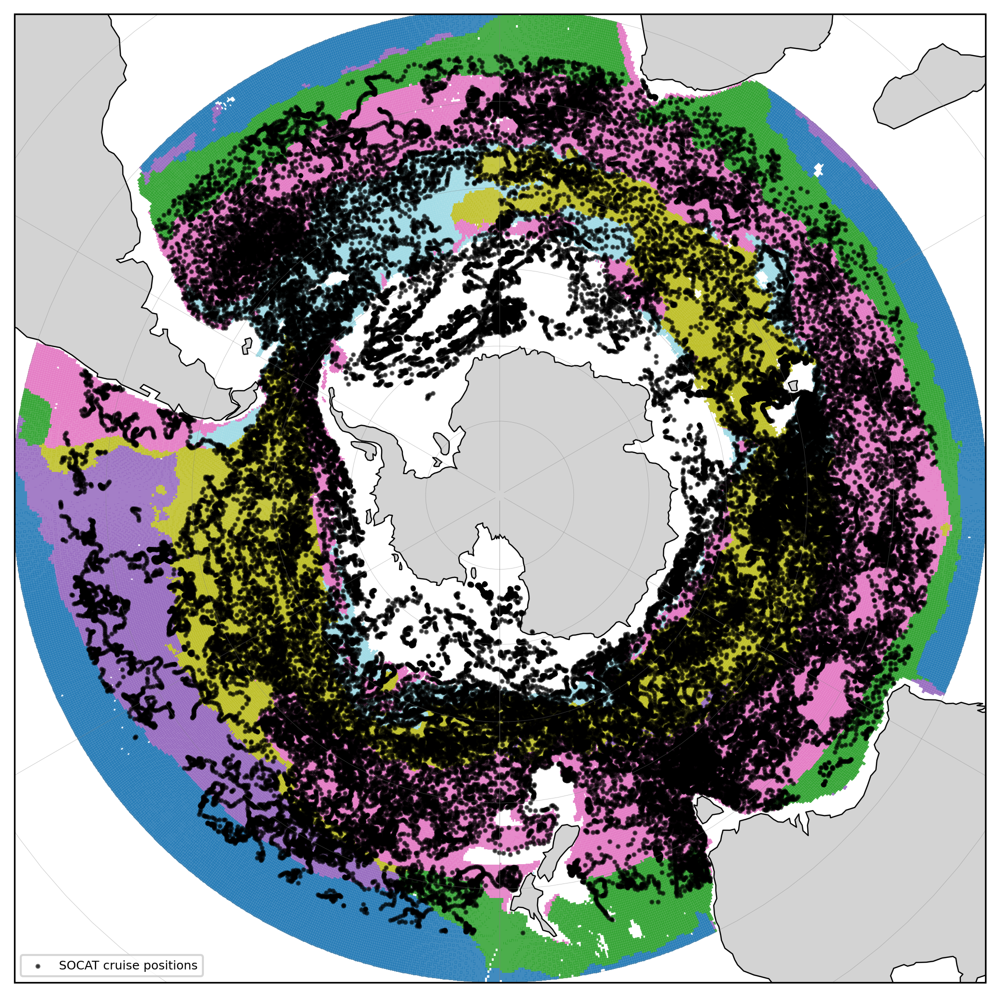

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

# bioregions = loaded xarray dataset
# It contains: bioregions["cluster"], bioregions["latitude"], bioregions["longitude"]

# Extract variables
clusters = bioregions["cluster"].values
lats = bioregions["latitude"].values
lons = bioregions["longitude"].values

# ---- SET UP MAP ----
fig = plt.figure(figsize=(7, 7), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo())
ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

# Base map
ax.coastlines(resolution='110m', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=0)
ax.gridlines(draw_labels=False, linewidth=0.2, color='gray', alpha=0.5)

# ---- ADD BIOREGIONS (categorical map) ----
# Define a discrete colormap
unique_vals = np.unique(clusters[~np.isnan(clusters)]).astype(int)
n_colors = len(unique_vals)
cmap = plt.cm.get_cmap("tab20", n_colors)

# Create a normalization mapping each cluster to a color class
norm = mcolors.BoundaryNorm(boundaries=np.arange(n_colors+1)-0.5, ncolors=n_colors)

# Plot raster grid
mesh = ax.pcolormesh(
    lons,
    lats,
    clusters,
    cmap=cmap,
    norm=norm,
    shading="nearest",
    transform=ccrs.PlateCarree(),
    zorder=1,     # underneath SOCAT points
    alpha=0.85
)

# ---- SCATTER SOCAT CRUISE POSITIONS ----
ax.scatter(
    df["longitude"],
    df["latitude"],
    s=2,
    color="k",
    transform=ccrs.PlateCarree(),
    alpha=0.6,
    label="SOCAT cruise positions",
    zorder=2
)

# Legend
ax.legend(
    loc='lower left',
    fontsize=6,
    frameon=True
)

plt.tight_layout()
plt.show()


In [68]:
# ===============================================================
# Extract year & month from BGC-Argo datetime
# ===============================================================

df["datetime"] = pd.to_datetime(df["datetime"])
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month

# ===============================================================
# Assign Southern Hemisphere seasons
# ===============================================================

def classify_season(month):
    if month in [6, 7, 8]:
        return "winter"     # JJA
    elif month in [9, 10, 11]:
        return "spring"     # SON
    elif month in [12, 1, 2]:
        return "summer"     # DJF
    elif month in [3, 4, 5]:
        return "autumn"     # MAM
    return None

df["season"] = df["month"].apply(classify_season)

# ===============================================================
# Per-season profile lists
# ===============================================================

cols = [
    "platform_number", "cycle_number", "datetime",
    "latitude", "longitude", "pco2", "pco2_error",
    "temperature", "salinity", "year", "month", "season"
]

df_winter_profiles  = df[df["season"] == "winter"][cols].copy()
df_spring_profiles  = df[df["season"] == "spring"][cols].copy()
df_summer_profiles  = df[df["season"] == "summer"][cols].copy()
df_autumn_profiles  = df[df["season"] == "autumn"][cols].copy()

# ===============================================================
# Helper: earliest year per platform
# ===============================================================

df_years = (
    df.groupby("platform_number")["year"]
      .min()
      .reset_index(name="earliest_year")
)

# ===============================================================
# Helper: summarize a seasonal profile dataframe
# Add:
#   - n_points
#   - earliest_year
#   - months (unique list for that season)
# ===============================================================

def summarize(season_df):

    # n_points per float
    df_counts = (
        season_df.groupby("platform_number")
        .size()
        .reset_index(name="n_points")
    )

    # unique months per float (sorted as "6, 7, 8")
    df_months = (
        season_df.groupby("platform_number")["month"]
        .apply(lambda x: ", ".join(map(str, sorted(x.unique()))))
        .reset_index(name="months")
    )

    # starting position (lat/lon at earliest datetime)
    df_start = (
        season_df.sort_values("datetime")
        .groupby("platform_number")
        .first()[["latitude", "longitude"]]
        .reset_index()
        .rename(columns={"latitude": "start_lat", "longitude": "start_lon"})
    )

    # merge all summaries
    summary = (
        df_counts
        .merge(df_years, on="platform_number", how="left")
        .merge(df_months, on="platform_number", how="left")
        .merge(df_start, on="platform_number", how="left")
        .sort_values(["n_points", "earliest_year"], ascending=[False, True])
        .reset_index(drop=True)
    )

    return summary


# ===============================================================
# Seasonal summaries
# ===============================================================

df_winter_floats = summarize(df_winter_profiles)
df_spring_floats = summarize(df_spring_profiles)
df_summer_floats = summarize(df_summer_profiles)
df_autumn_floats = summarize(df_autumn_profiles)


In [206]:
pd.set_option("display.max_rows", None)      # show all rows
pd.set_option("display.max_columns", None)   # show all columns
pd.set_option("display.width", None)         # no line wrapping
pd.set_option("display.max_colwidth", None)  # don't shorten column text

display(df_winter_floats.sort_values(by="months"))


,platform_number,n_points,earliest_year,months,start_lat,start_lon
514,5907054,1,2024,6,-38.417200,113.462600
475,5905382,3,2018,6,-63.863000,5.002000
476,5905383,3,2018,6,-66.196000,5.294000
478,5906304,3,2021,6,-35.332000,-151.753000
481,2900129,2,2007,6,-64.308000,119.908000
489,5906005,2,2019,6,-59.151000,-27.450000
490,5906210,2,2020,6,-64.919645,58.195962
498,2900117,1,2007,6,-64.185347,93.174622
486,5904670,2,2016,6,-63.423412,93.026640
501,5902100,1,2008,6,-45.836000,75.337000


In [217]:
df_july_counts = (
    df[df["month"] == 7]
      .groupby("platform_number")
      .size()
      .reset_index(name="n_points")
      .sort_values("n_points", ascending=False)
)


In [218]:
df_july_counts

,platform_number,n_points
13,1901339,89
12,1901338,87
253,5904882,82
169,5903678,63
162,5903264,51
259,5905030,46
152,5903225,36
170,5903679,35
155,5903248,31
161,5903260,30


/tmp/ipykernel_2394958/4106286237.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_vals))


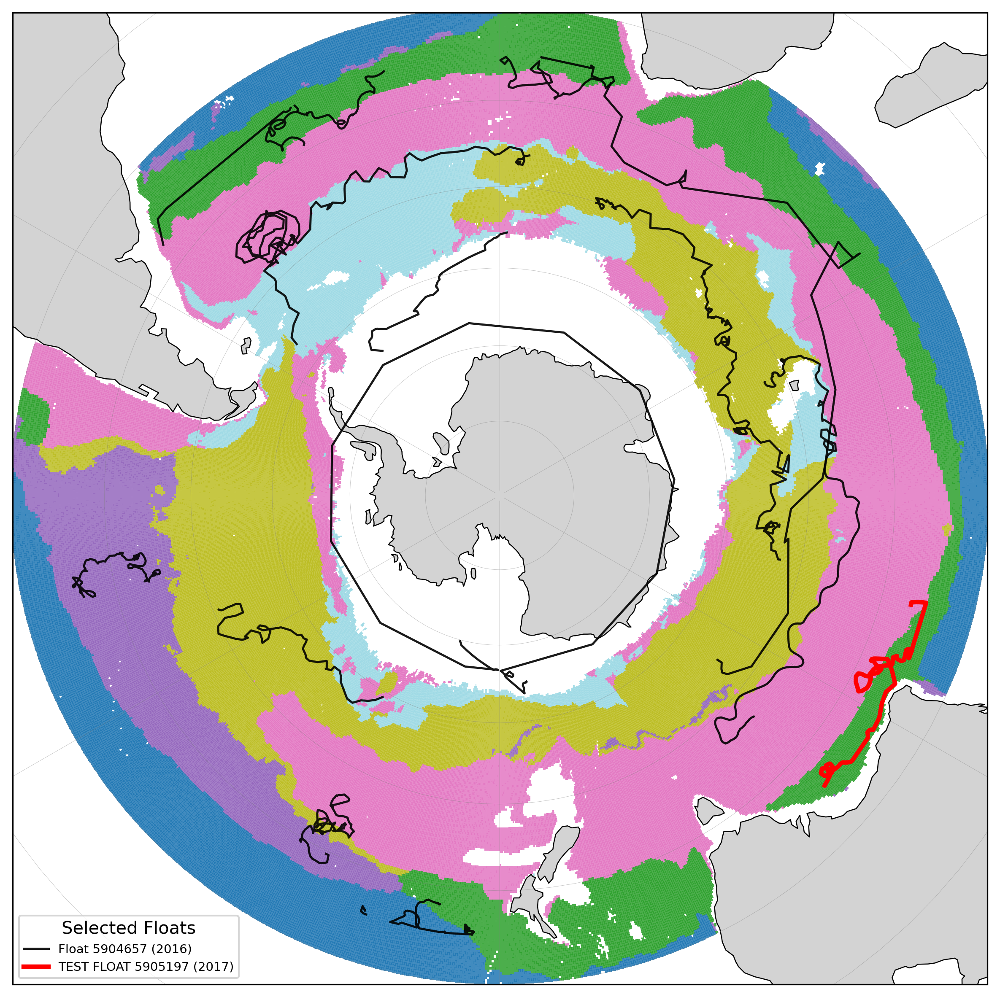

In [219]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

# ===============================================================
# 1. Select floats you keep + 1 test float
# ===============================================================

keep_platforms = [
    # --------- SUMMER ---------
    5904657,   # summer
    5904841,   # summer
    6902905,   # summer
    5903717,   # summer

    # --------- AUTUMN ---------
    2902130,   # autumn
    5901742,   # autumn
    5906246,   # autumn
    5906487,   # autumn

    # --------- SPRING ---------
    3901497,   # spring
    5901047,   # spring
    5905142,   # spring
    6900896,   # spring

    # --------- WINTER ---------
    2903455,   # winter
    5904694,    # winter
    5900422,
]


# → The one you want to test will be highlighted in RED
test_platform =  5905197   # <<< just change this number to test another

# Full list of floats to load (keep + test)
platforms_to_plot = keep_platforms + [test_platform]

df_sel = df[df["platform_number"].isin(platforms_to_plot)].copy()

# ===============================================================
# 2. Extract bioregion raster
# ===============================================================

clusters = bioregions["cluster"].values
lats = bioregions["latitude"].values
lons = bioregions["longitude"].values

# ===============================================================
# 3. MAP SETUP
# ===============================================================

fig = plt.figure(figsize=(8, 8), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo())
ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

ax.coastlines(resolution="110m", linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

unique_vals = np.unique(clusters[~np.isnan(clusters)]).astype(int)
cmap = plt.cm.get_cmap("tab20", len(unique_vals))
norm = mcolors.BoundaryNorm(
    boundaries=np.arange(len(unique_vals)+1) - 0.5,
    ncolors=len(unique_vals)
)

ax.pcolormesh(
    lons, lats, clusters,
    cmap=cmap, norm=norm,
    shading="nearest",
    transform=ccrs.PlateCarree(),
    zorder=1,
    alpha=0.85
)

# ===============================================================
# 4. PLOT FLOAT TRAJECTORIES
# ===============================================================

for p in keep_platforms:
    df_f = df_sel[df_sel["platform_number"] == p]
    if len(df_f) == 0:
        continue

    year = int(df_f["year"].min())

    ax.plot(
        df_f["longitude"],
        df_f["latitude"],
        transform=ccrs.PlateCarree(),
        linewidth=1.2,
        color="black",
        alpha=0.9,
        zorder=3,
        label=f"Float {p} ({year})" if p == keep_platforms[0] else ""  # avoid legend spam
    )

# Plot the test float in RED
df_test = df_sel[df_sel["platform_number"] == test_platform]

if len(df_test) > 0:
    test_year = int(df_test["year"].min())

    ax.plot(
        df_test["longitude"],
        df_test["latitude"],
        transform=ccrs.PlateCarree(),
        linewidth=2.5,
        color="red",
        zorder=4,
        label=f"TEST FLOAT {test_platform} ({test_year})"
    )

# Legend
ax.legend(
    loc="lower left",
    fontsize=7,
    title="Selected Floats",
    frameon=True
)

plt.tight_layout()
plt.show()


In [220]:
# 1. Count points per expocode
counts = df_sel.groupby("platform_number").size().rename("n_points")

# 2. Unique expocode list (one row per cruise)
df_sel_unique = (
    df_sel.drop_duplicates(subset="platform_number")
          .sort_values(by="year")
          .merge(counts, on="platform_number", how="left")
)

In [221]:
df_sel_unique.sort_values(by="season")

,datetime,latitude,longitude,platform_number,cycle_number,pco2,pco2_error,temperature,salinity,year,month,season,n_points
2,2008-03-22 21:55:32.997892608,-65.280000,-39.020000,5901742,1,327.715485,16.193001,-1.558600,34.089203,2008,3,autumn,91
5,2014-04-05 11:38:00.000000000,-50.100390,18.260887,2902130,1,380.139404,17.989401,3.172340,33.777031,2014,4,autumn,183
10,2017-04-17 07:15:56.999985920,-35.594200,131.753400,5905197,1,363.351318,24.472834,17.424166,35.198460,2017,4,autumn,201
13,2020-03-27 15:50:31.001681920,-35.564000,1.129000,5906246,1,384.548004,20.306999,19.612511,35.022202,2020,3,autumn,55
14,2022-03-13 22:51:10.002434304,-35.081000,-28.338000,5906487,3,410.549011,22.049000,21.851601,35.634743,2022,3,autumn,8
1,2005-10-28 18:57:18.000866816,-44.707000,-151.911000,5901047,1,354.671997,17.315001,10.075000,34.459999,2005,10,spring,148
3,2010-10-29 19:23:00.000000000,-36.547000,15.074000,6900896,3,345.621002,17.326000,17.375999,35.591000,2010,10,spring,35
6,2014-10-25 11:39:59.999999744,-35.845058,-27.790712,3901497,1,349.606995,19.321798,15.012285,35.393787,2014,10,spring,170
11,2017-10-26 09:56:46.001047040,-39.306000,-29.177000,5905142,1,367.490356,21.487000,15.278412,35.551155,2017,10,spring,97
4,2012-02-19 07:52:10.000827904,-65.027000,171.832000,5903717,1,344.023010,31.379999,-0.057000,33.205139,2012,2,summer,72


/tmp/ipykernel_2394958/2786762988.py:63: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_vals))


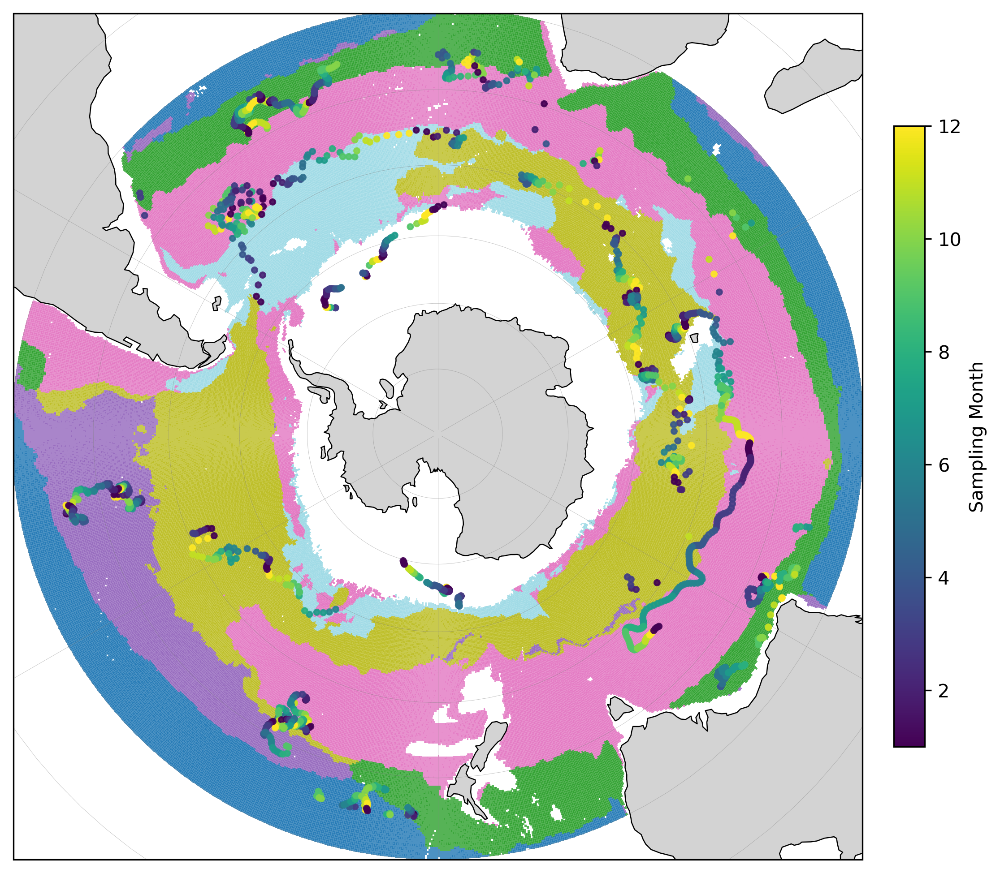

In [222]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

# ===============================================================
# 1. Updated: Floats you want to keep (5905197 added to AUTUMN)
# ===============================================================

keep_platforms = [
    # --------- SUMMER ---------
    5904657,
    5904841,
    6902905,
    5903717,

    # --------- AUTUMN ---------
    2902130,
    5901742,
    5906246,
    5906487,
    5905197,     # ← added to AUTUMN

    # --------- SPRING ---------
    3901497,
    5901047,
    5905142,
    6900896,

    # --------- WINTER ---------
    2903455,
    5904694,
    5900422,
]

# Subset data
df_sel = df[df["platform_number"].isin(keep_platforms)].copy()

# ===============================================================
# 2. Extract bioregion raster
# ===============================================================

clusters = bioregions["cluster"].values
lats = bioregions["latitude"].values
lons = bioregions["longitude"].values

# ===============================================================
# 3. MAP SETUP
# ===============================================================

fig = plt.figure(figsize=(8, 8), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo())
ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

ax.coastlines(resolution="110m", linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

# Bioregion shading
unique_vals = np.unique(clusters[~np.isnan(clusters)]).astype(int)
cmap = plt.cm.get_cmap("tab20", len(unique_vals))
norm = mcolors.BoundaryNorm(
    boundaries=np.arange(len(unique_vals)+1) - 0.5,
    ncolors=len(unique_vals)
)

ax.pcolormesh(
    lons, lats, clusters,
    cmap=cmap, norm=norm,
    shading="nearest",
    transform=ccrs.PlateCarree(),
    zorder=1,
    alpha=0.80
)

# ===============================================================
# 4. PLOT FLOAT TRAJECTORIES COLORED BY MONTH
# ===============================================================

# month colormap
month_cmap = plt.cm.viridis
month_norm = mcolors.Normalize(vmin=1, vmax=12)

for p in keep_platforms:
    df_f = df_sel[df_sel["platform_number"] == p]
    if df_f.empty:
        continue

    ax.scatter(
        df_f["longitude"],
        df_f["latitude"],
        c=df_f["month"],
        cmap=month_cmap,
        norm=month_norm,
        s=8,
        transform=ccrs.PlateCarree(),
        alpha=0.9,
        zorder=3
    )

# Colorbar for month
cb = plt.colorbar(
    plt.cm.ScalarMappable(norm=month_norm, cmap=month_cmap),
    ax=ax,
    orientation="vertical",
    shrink=0.6,
    pad=0.03
)
cb.set_label("Sampling Month")

plt.tight_layout()
plt.show()


## check the independent validation file after script 0_

Floats found: [5900422 5901047 5901742 6900896 5903717 2902130 3901497 5904657 5904694
 5904841 5905197 5905142 6902905 5906246 5906487 2903455]


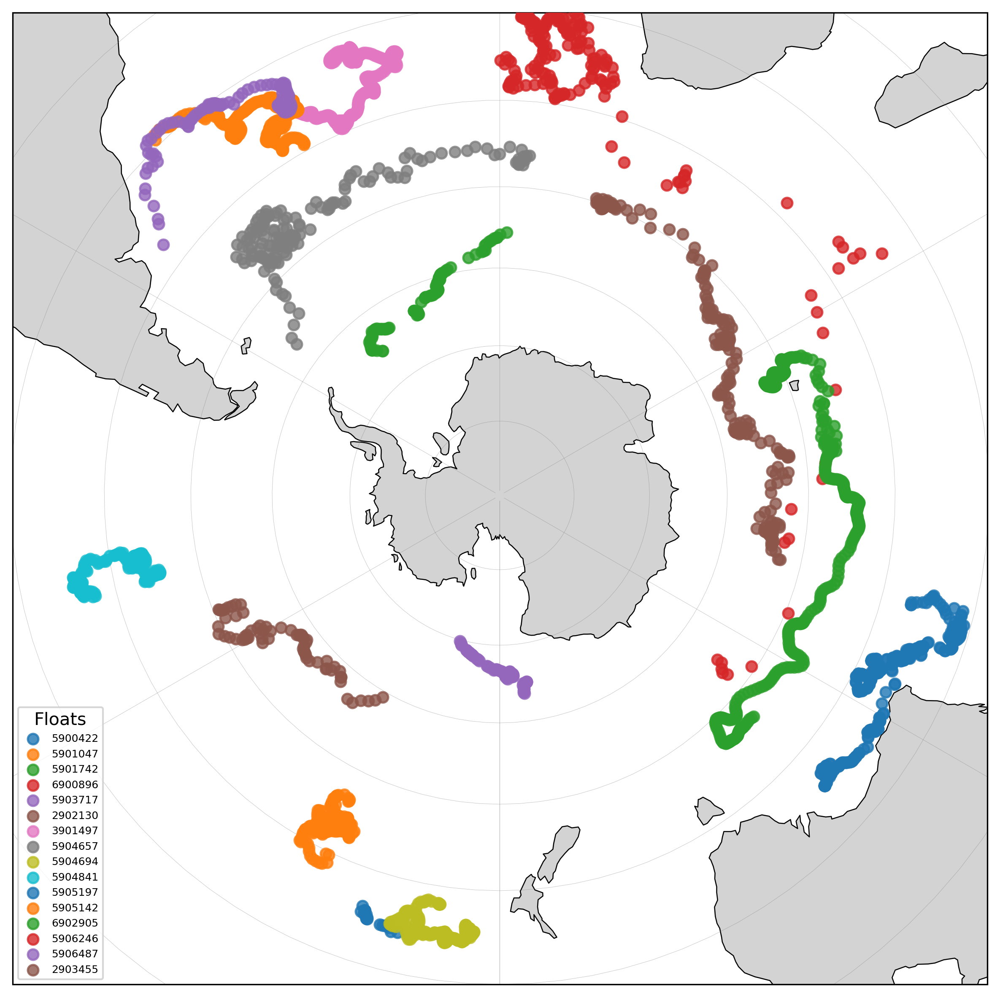

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===============================================================
# 1. Load CSV
# ===============================================================

csv_path = (
    "/home/ldelaigue/Documents/Python/SOCAT-OSSE-SO/"
    "MODEL_FLOATS_v2/processing_steps/independent_validation/"
    "pco2_independent_validation_data.csv"
)

df = pd.read_csv(csv_path)

# List floats
all_platforms = df["platform_number"].unique()
print("Floats found:", all_platforms)

# ===============================================================
# 2. MAP SETUP
# ===============================================================

fig = plt.figure(figsize=(8, 8), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo())
ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

ax.coastlines(resolution="110m", linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

# ===============================================================
# 3. PLOT FLOAT TRAJECTORIES (lat/lon only)
# ===============================================================

for p in all_platforms:
    df_f = df[df["platform_number"] == p]

    ax.scatter(
        df_f["longitude"],
        df_f["latitude"],
        transform=ccrs.PlateCarree(),
        linewidth=1.2,
        alpha=0.8,
        zorder=3,
        label=str(p)
    )

# ===============================================================
# 4. Legend
# ===============================================================

ax.legend(
    loc="lower left",
    fontsize=6,
    title="Floats",
    frameon=True
)

plt.tight_layout()
plt.show()
